# Clustering
This exercise involves working with K-means clustering, _Mean-shift clustering_, and _Agglomerative clustering_ on the poses data used for the exercises in week 2
 and week 10
. The task includes applying and experimenting with each method and then comparing their outcomes. The comparison will be conducted by clustering a sequence of human poses using these three methods in similar steps.
The dataset tensor contains 1403 pose sequences. Each sequence is a 100-frames time series capturing human poses. Each pose consists of 25 skeletal joints, where each joint is defined by an x and y coordinate ($25*2$). The shape of the dataset tensor is $(1403, 100, 25*2)$. For this exercise, you will use a single pose sequence of 100 frames and apply clustering to the sequence.
## Task overview
For each clustering method you will:
- Implement the method.
- Plot the clusters in the sequence.
- Plot the cluster centers.


<article class="message">
    <div class="message-body">
        <strong>List of individual tasks</strong>
        <ul style="list-style: none;">
            <li>
            <a href="#loading00">Task 1: Introduction</a>
            </li>
            <li>
            <a href="#loading_files">Task 2: Setting up the data</a>
            </li>
            <li>
            <a href="#loading">Task 3: Fitting the algorithm</a>
            </li>
            <li>
            <a href="#loading2">Task 4: K-means clustering visualization</a>
            </li>
            <li>
            <a href="#loading02">Task 5: Cluster characteristics</a>
            </li>
            <li>
            <a href="#loading3">Task 6: Elbow Method</a>
            </li>
            <li>
            <a href="#loading4">Task 7: Fitting the mean-shift algorithm</a>
            </li>
            <li>
            <a href="#loading5">Task 8: Visualizing clusters</a>
            </li>
            <li>
            <a href="#loading9">Task 9: Reflection and the bandwith parameter</a>
            </li>
            <li>
            <a href="#loading10">Task 10: Dendrograms</a>
            </li>
            <li>
            <a href="#loading11">Task 11: Fitting the agglomerative clustering alg…</a>
            </li>
            <li>
            <a href="#loading12">Task 12: Agglomerative clustreing algorithm mean …</a>
            </li>
            <li>
            <a href="#loading13">Task 13: Compare and reflect on the methods</a>
            </li>
        </ul>
    </div>
</article>


---
**Task 1 (easy): Introduction💡**
This task is about understanding the data.
1. Explain the benefits of applying a clustering method to a sequence of pose data.
2. Identify possible pitfalls.


---

In [21]:
## 1. Explain the benefits of applying a clustering method to a sequence of pose data.
# Discover patterns in the data
# Clusters might represent different movements, activities etc.
# Can highlight outliers 
## 2. Identify possible pitfalls.
# Each pose is dependent on the previous pose, so clustering might not be the best method
# Might be hard to interpret the clusters
# High dimensionality of the data

The following cells import libraries and provide functions for plotting the poses:


In [22]:
import numpy as np
import matplotlib.pyplot as plt
import warnings
import seaborn as sns
from sklearn.cluster import MeanShift
from sklearn.cluster import KMeans
from sklearn.cluster import AgglomerativeClustering
from scipy.spatial.distance import pdist, squareform
import scipy.cluster.hierarchy as shc
from scipy.cluster.hierarchy import dendrogram, linkage
from clustering_utils import *


# Suppress the specific warning
warnings.filterwarnings("ignore")


---
**Task 2 (easy): Setting up the data👩‍💻**
1. Run the cell below to load and reshape the dataset, and extract a single pose sequence of 100 frames. 
2. Choose the 100th pose sequence as the dataset.


---

In [23]:
data = np.load('poses_norm.npy')
N,T,D,C = data.shape
reshaped_data = data.reshape(N,T,D*C) # Reshape from 4D to 3D
sequence = reshaped_data[191] # not the 100th sequence
print(sequence.shape)

(100, 50)


## K-means Clustering
In this  exercise you will use k-means clustering on a pose sequence. 

---
**Task 3 (easy): Fitting the algorithm👩‍💻**
1. Run the cell below to create an instance of the `KMeans`
 class with 3 clusters and to find clusters in the sequence.


---

In [24]:
# Specify the number of clusters (k)
k = 7

# Create KMeans 
kmeans = KMeans(n_clusters=k, random_state=42)

# Fit to the data
# Works by assigning each data point to the nearest cluster center and then setting the cluster centers to the mean
# Does this iteratively until the cluster centers do not change
kmeans.fit(sequence)

KMeans(n_clusters=7, random_state=42)


---
**Task 4 (easy): K-means clustering visualization👩‍💻**
1. Use the [documentation on the `labels_`
 attribute.](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html)
 to obtain cluster labels. 
2. Use the `plot_single_pose`
 function to color each pose in the pose sequence according to which cluster it belongs to. 


---

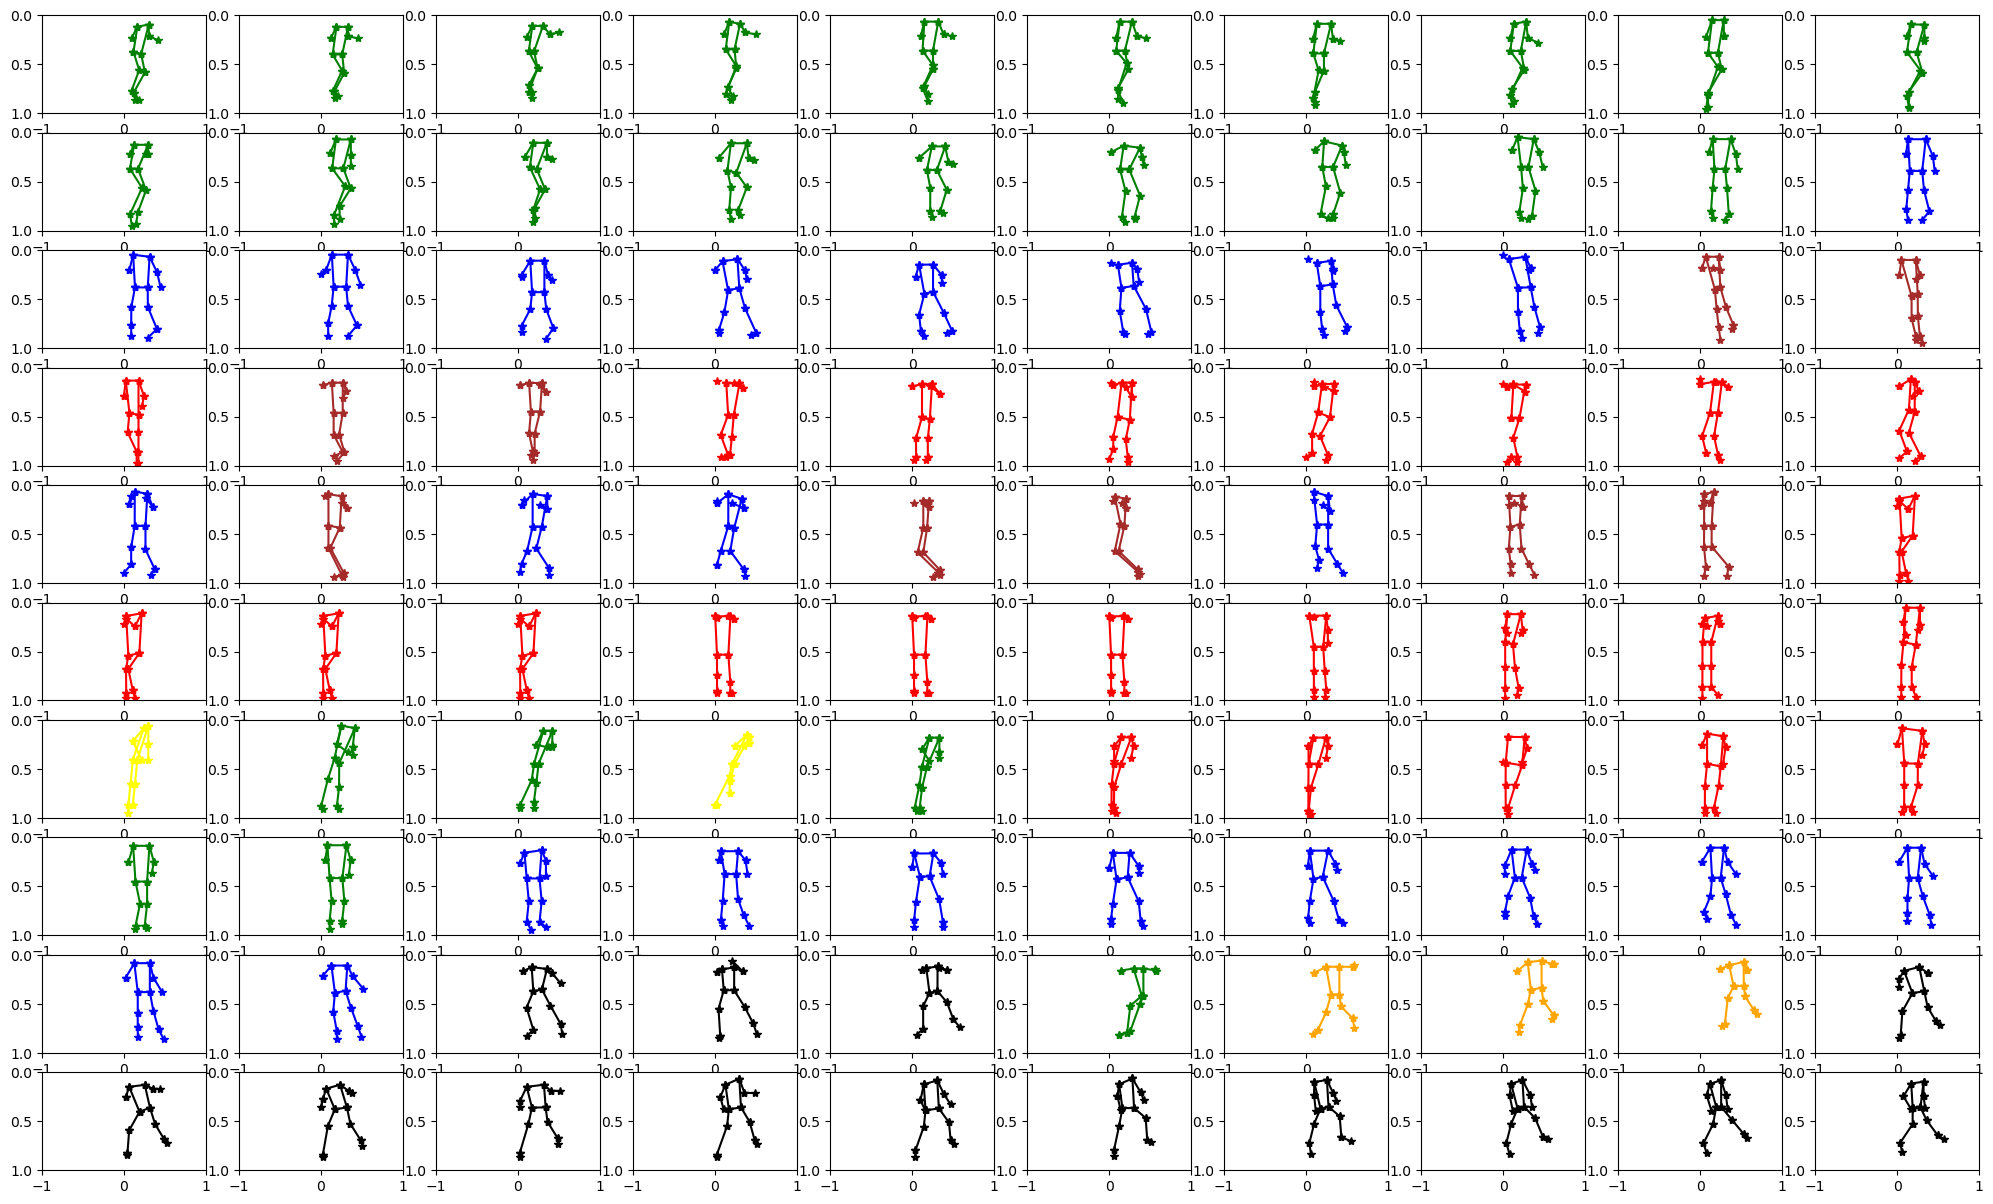

In [25]:
# Get cluster labels
cluster_labels = kmeans.labels_

# Get cluster centers
centroids = kmeans.cluster_centers_

# You can now use 'cluster_labels' to see which cluster each frame belongs to
# 'centroids' contains the coordinates of the cluster centers
colors = {0: 'red', 1: 'blue', 2: 'green', 3: "orange", 4: "black", 5: "brown", 6: "yellow", 7: "cyan"}  # Map cluster labels to colors
plt.figure(figsize=(25,15))
for i in range(len(sequence)):
    plt.subplot(10, 10, i + 1)
    plot_single_pose(sequence[i], c=colors[cluster_labels[i]], head=False)
    plt.ylim(1, 0)
    plt.xlim(-1, 1)


---
**Task 5 (easy): Cluster characteristics💡**
1. Run the cell below to extract and plot the cluster centers.

2. Visually inspect the results and identify the characteristics of the poses in each cluster: 
    - What distinguishes the clusters?
    - What do the cluster centers represent?
    - What do the clusters reveal about movements?


3. Reason about the choice of 3 clusters and the effect on the result.

4. Change the random state and fit the model again. Explain whether you obtain different groupings and why? 



---

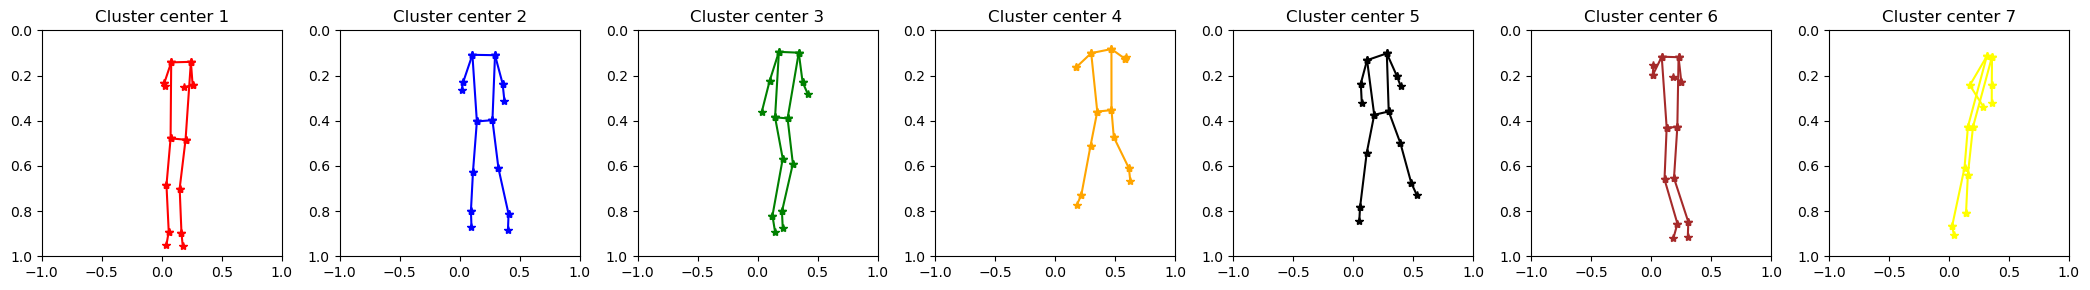

In [26]:
num_centroids = len(centroids)
# Set up subplots
fig, axes = plt.subplots(1, num_centroids, figsize=(num_centroids * 3, 3))

# Assuming you have a function plot_single_pose defined
for i in range(len(centroids)):
    plt.subplot(1, len(centroids), i+1)
    plt.title(f'Cluster center {i+1}')
    plot_single_pose(centroids[i], c=colors[i], head=False)
    plt.ylim(1, 0)
    plt.xlim(-1, 1)

plt.tight_layout()
plt.show()


# write your reflection here

## 2. Visually inspect the results and identify the characteristics of the poses in each cluster: 

## What distinguishes the clusters?
# Positins of arms, legs, waist etc. 
# The direction they are facing

## What do the cluster centers represent?
# The average pose of the cluster

## What do the clusters reveal about movements?
# Different movements, activities etc.
# Different phases of a movement
    # Could look like a jump where
    # 1. The person is getting ready to jump
    # 2. The person is in the air
    # 3. The person is landing

## 3. Reason about the choice of 3 clusters and the effect on the result.
# Keeps it basic. Low number of clusters make it easier to distinguish between them
# Might not be enough clusters to represent all the different poses in the data
# Depends on whether you want to distinguish between different movements or different phases of one movement

## 4. Change the random state and fit the model again. Explain whether you obtain different groupings and why?
# The random state is the initial cluster centers
# If you change the random state you might get different clusters in the end 


---
**Task 6 (medium): Elbow Method👩‍💻💡**
This task uses the Elbow Method to choose the number of clusters `k`
. The cell below:
- Applies k-means clustering to the sequence using each `k`
 in `k_range`
.
- Extracts the within-cluster sum of squares using [`kmeans.intertia_`
](https://scikit-learn.org/1.5/modules/generated/sklearn.cluster.KMeans.html)
 and stores it in a list.
- Plots the within-cluster sum of squares as a function of the number of clusters (elbow curve as displayed below) 

1. Visually determine the optimal number of clusters.

2. Calculate the rate of change for the elbow curve and plot its absolute value. Use the curve to determine the optimal `k`
.

3. Revisit and run the previous tasks ([Task 3](#loading), [Task 4](#loading2) and [Task 5](#loading02) ) with the optimal number of clusters. 

4. How does the elbow method influence the results in the previous tasks?



---

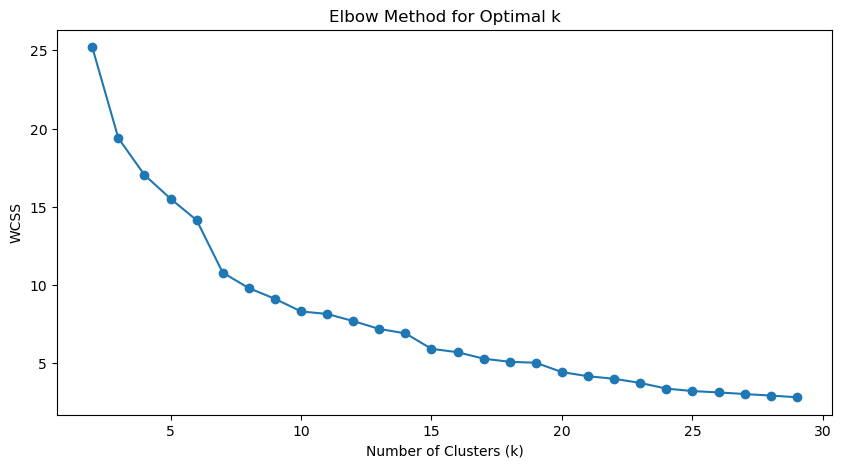

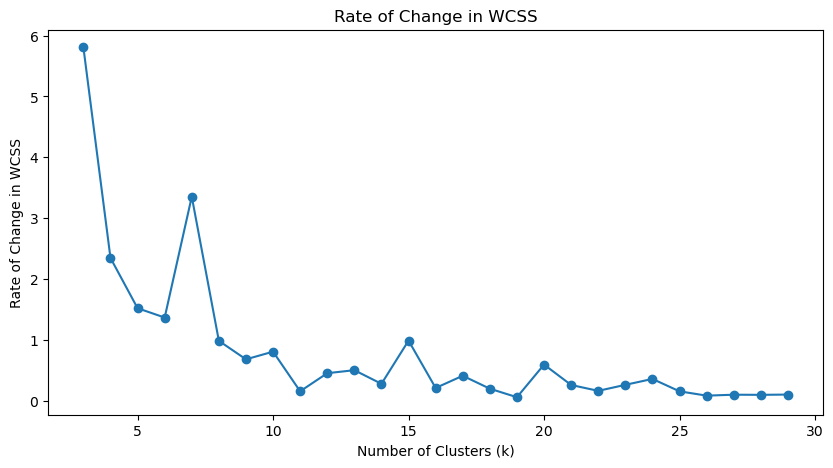

In [27]:
# Find the optimal k using the elbow method
k_range = range(2, 30) # values for the number of clusters `k`
inertia = []

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(sequence)
    inertia.append(kmeans.inertia_)

# Plot the elbow curve
plt.figure(figsize=(10, 5))
plt.plot(k_range, inertia, marker='o')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('WCSS')
plt.title('Elbow Method for Optimal k')
plt.show()

# Rate of change in the elbow curve
# To determine where this rate of change drops most
# The differense between the inertia of k and k+1
rate_of_change = np.diff(inertia)
plt.figure(figsize=(10, 5))
plt.plot(k_range[1:], np.abs(rate_of_change), marker='o', label='Rate of Change (Absolute Value)')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Rate of Change in WCSS')
plt.title('Rate of Change in WCSS')
plt.show()

In [28]:
# 1. Visually determine the optimal number of clusters.
# The optimal number of clusters is where the curve starts to flatten out
# Meaning, where the rate of change is decreasing
# In this case it is not exaclty clear, but starts to flatten around 5

# Looking at rate of change, optimal k seems to be 7
# After 7 the rate of change is not as big as before

# How does the elbow method influence the results in the previous tasks?
# Some of the clusters are more distinct and the poses are more similar within the clusters
# Some clusters seem to be more similar to each other

## Mean-shift Clustering
This exercise is about applying mean-shift clustering to the sequence of human poses. 

---
**Task 7 (easy): Fitting the mean-shift algorithm👩‍💻**
1. Run the cell below to:    - create an instance of the `MeanShift()`
 class with a bandwith of 0.629 
    - cluster the pose sequence.




---

In [29]:
# Perform Mean Shift clustering
mean_shift = MeanShift(bandwidth=0.629)
mean_shift.fit(sequence)
# bandwidt is the radius of the area around each data point

MeanShift(bandwidth=0.629)


---
**Task 8 (easy): Visualizing clusters👩‍💻**
1. Extract the cluster labels for each pose in the sequence. Use the `labels_`
 attribute as described in the [documentation on mean-shift clustering.](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.MeanShift.html)

2. Visualize the pose sequence, assigning a distinct color to each pose based on its cluster.
3. Extract and plot the cluster centers using the `cluster_centers_`
 attribute.


---

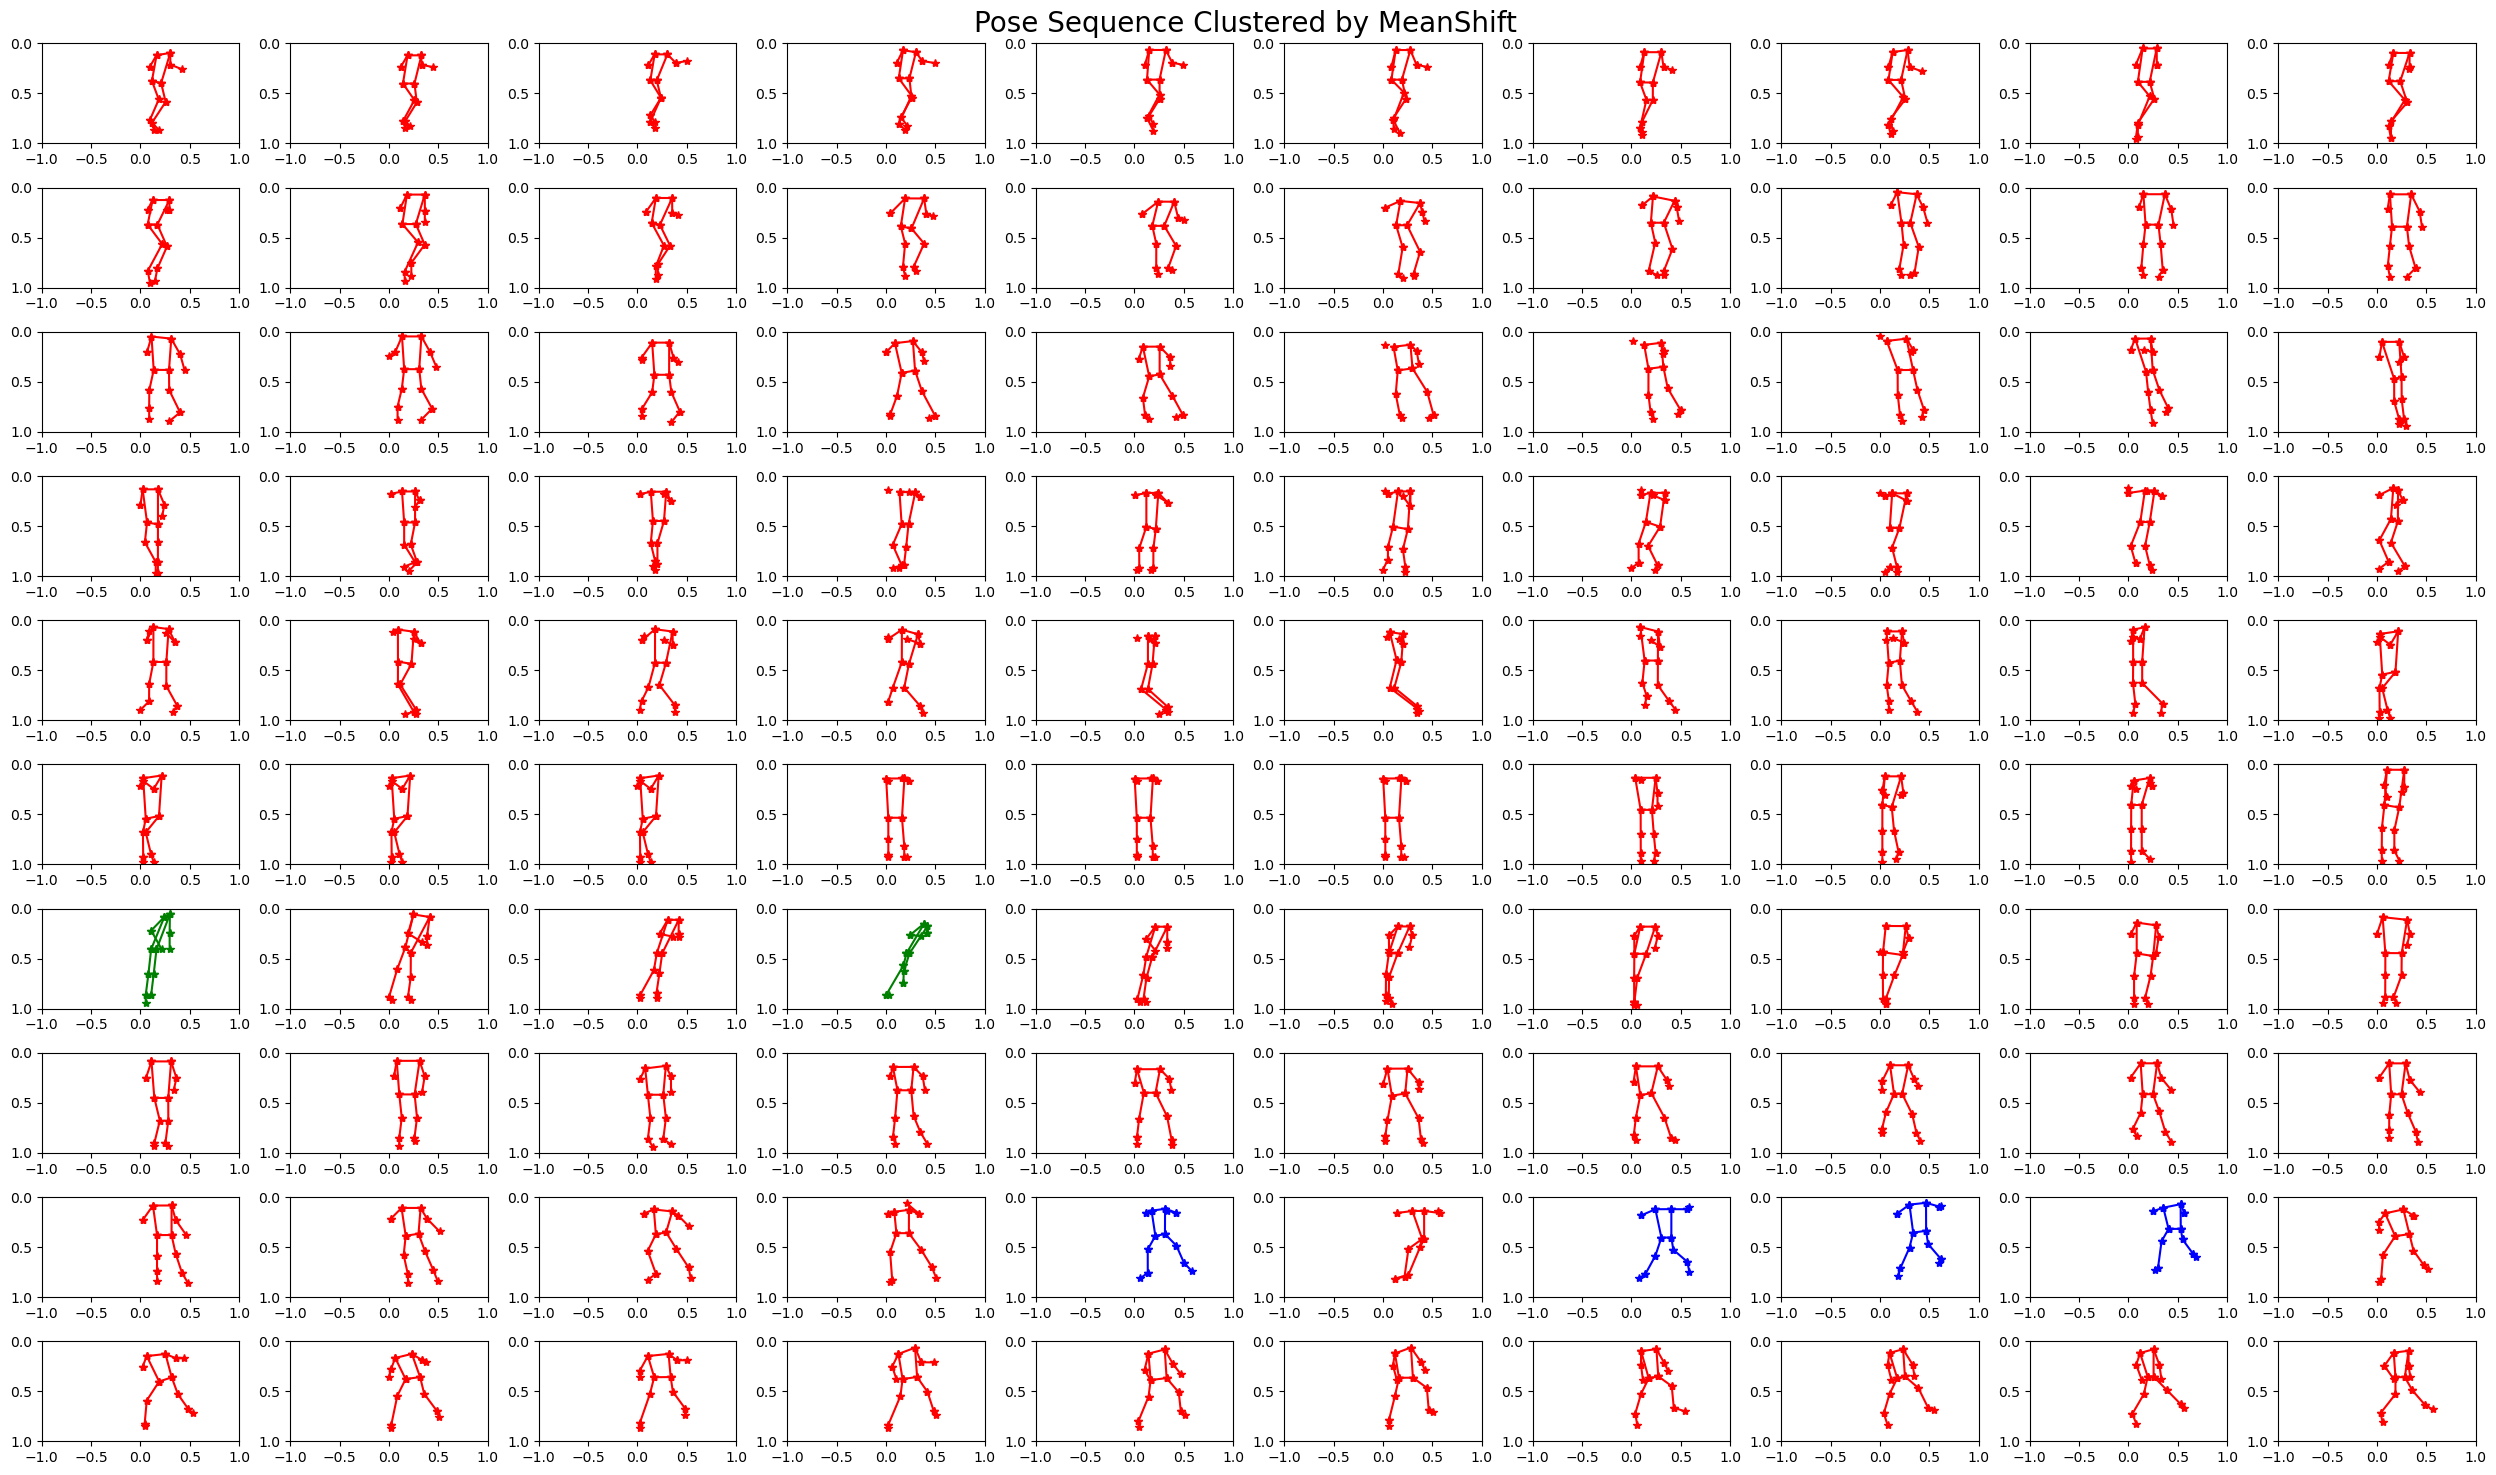

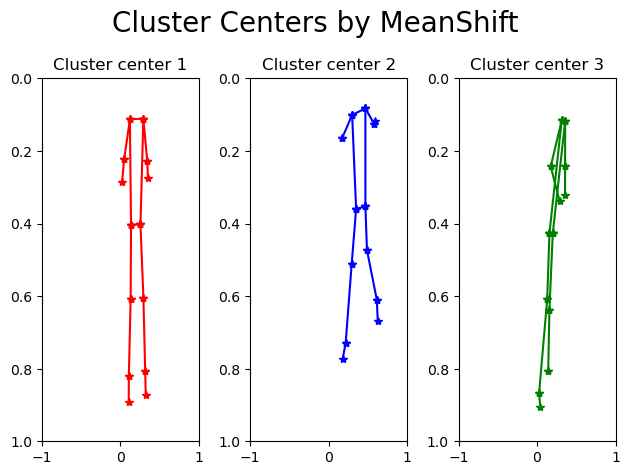

In [32]:
# Extract cluster labesl and cluster centers
cluster_labels = mean_shift.labels_
centroids = mean_shift.cluster_centers_


# Visualize the pose sequence, assigning a distinct color to each cluster
plt.figure(figsize=(25,15))
for i in range(len(sequence)):
    plt.subplot(10, 10, i + 1)
    plot_single_pose(sequence[i], c=colors[cluster_labels[i]], head=False)
    plt.ylim(1, 0)
    plt.xlim(-1, 1)
plt.suptitle('Pose Sequence Clustered by MeanShift', fontsize=20)
plt.tight_layout()
plt.show()

# Extract and plot centroids
for i in range(len(centroids)):
    plt.subplot(1, len(centroids), i+1)
    plt.title(f'Cluster center {i+1}')
    plot_single_pose(centroids[i], c=colors[i], head=False)
    plt.ylim(1, 0)
    plt.xlim(-1, 1)
plt.suptitle('Cluster Centers by MeanShift', fontsize=20)
plt.tight_layout()
plt.show()




---
**Task 9 (easy): Reflection and the bandwith parameter👩‍💻💡**
1. Visually examine the plots. What are the characteristics of the poses belonging to each cluster?
2. What effect does decreasing and increasing the bandwidth parameter by 0.2 (0.829 / 0.429) have and why?


**Info**
You might encounter longer run times for lower bandwith values.


---

In [33]:
## 1. Visually examine the plots. What are the characteristics of the poses belonging to each cluster?
# Cluster 1: Almost all of the poses
## The poses in cluster 1 differs much
# Cluster 2: Looks like a person i a jumo, shoulders high, legs spread
# Cluster 3: Person facing the right, almost becoming a line, only two poses


## 2. What effect does decreasing and increasing the bandwidth parameter by 0.2 (0.829 / 0.429) have and why?
# Higher bandwidth: Only two clusters, 1 and 3
## Almost all poses in cluster 1, only the two looking much to the right is in 3
## A larger neighborhood size smooths out the density estimation, leading to broader, less specific clusters.
## Reduces cluster granularity, potentially missing finer pose distinctions.
## Faster computation, as fewer clusters simplify the density estimation.
## Results in fewer clusters as larger bandwidths merge nearby dense regions into a single cluster.

# Lower bandwidth: More clusters, 1, 2, 3, 4, 5, 6, 7, 8
## More clusters, more specific clusters
## Creates more clusters since smaller bandwidths detect finer density regions.
## Can lead to over-clustering (splitting similar poses into multiple clusters).
## Longer run times due to more complex calculations.

## Agglomerative Clustering
This exercise is about applying hierarchical clustering to the human poses dataset.

---
**Task 10 (easy): Dendrograms👩‍💻💡**
1. Run the cell below to generate a dendrogram. 
2. How many clusters would result from setting the distance threshold to: 0.5, 1.5, 3.0, 4?
3. What types of relationships can agglomerative clustering reveal that non-hierarchical methods might miss?


---

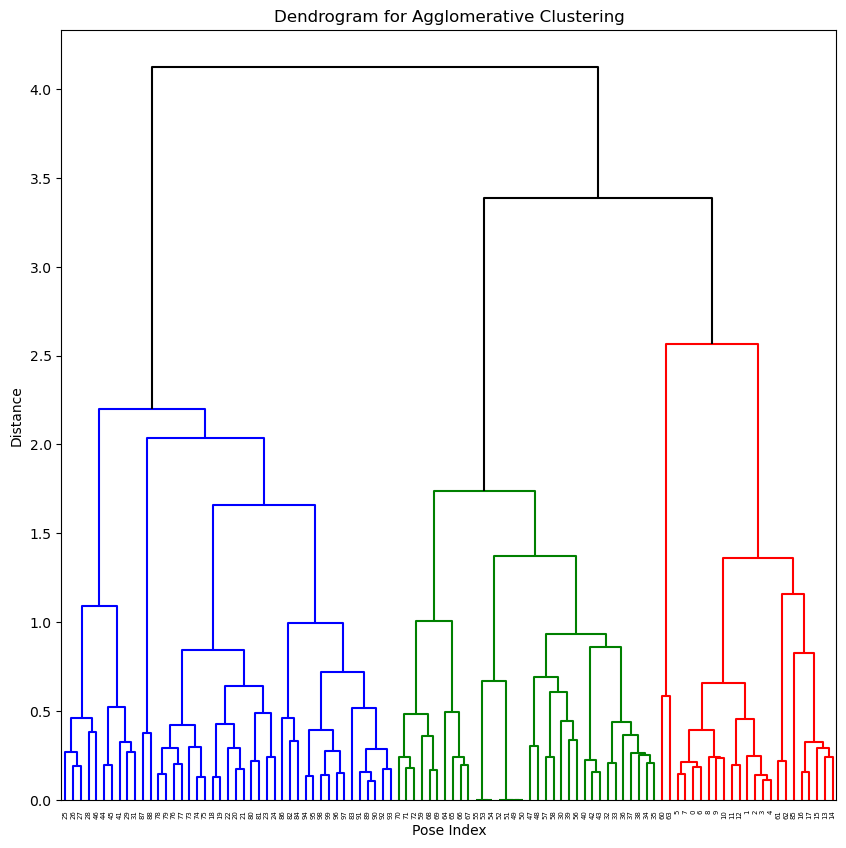

In [34]:
colors = {0: 'black', 1: 'blue', 2: 'green', 3: 'red'}
sns.set_palette([colors[i] for i in range(len(colors))])
shc.set_link_color_palette(None)
plt.figure(figsize=(10,10))
plt.title('Dendrogram for Agglomerative Clustering')
plt.xlabel('Pose Index')
plt.ylabel('Distance')
linkage_matrix = shc.linkage(sequence, method ='ward', metric="euclidean")
Dendrogram = shc.dendrogram(linkage_matrix)

In [35]:
## 2. How many clusters would result from setting the distance threshold to: 0.5, 1.5, 3.0, 4?
# Draw a horizontal line at the distance threshold to determine the number of clusters (looking up)
# 0,5 = Many (20-30)
# 1,5 = 8
# 3 = 3
# 4 = 2

## 3. What types of relationships can agglomerative clustering reveal that non-hierarchical methods might miss?
# Hierarchical relationships between clusters
# For example, two similar poses might first form a small cluster, which later joins a larger cluster.
# Helps decide the number of clusters based on the dendrogram


---
**Task 11 (easy): Fitting the agglomerative clustering algorithm👩‍💻**
The cell below creates an instance of the `AgglomerativeClustering()`
 class. The [documentation on agglomerative clustering is given here.](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.AgglomerativeClustering.html)

1. Select the distance threshold that results in 3 clusters, then apply agglomerative clustering on the sequence. 
2. Extract the cluster labels for each pose in the sequence.
3. Visualize the pose sequence by assigning a distinct color to each pose based on its cluster.


---

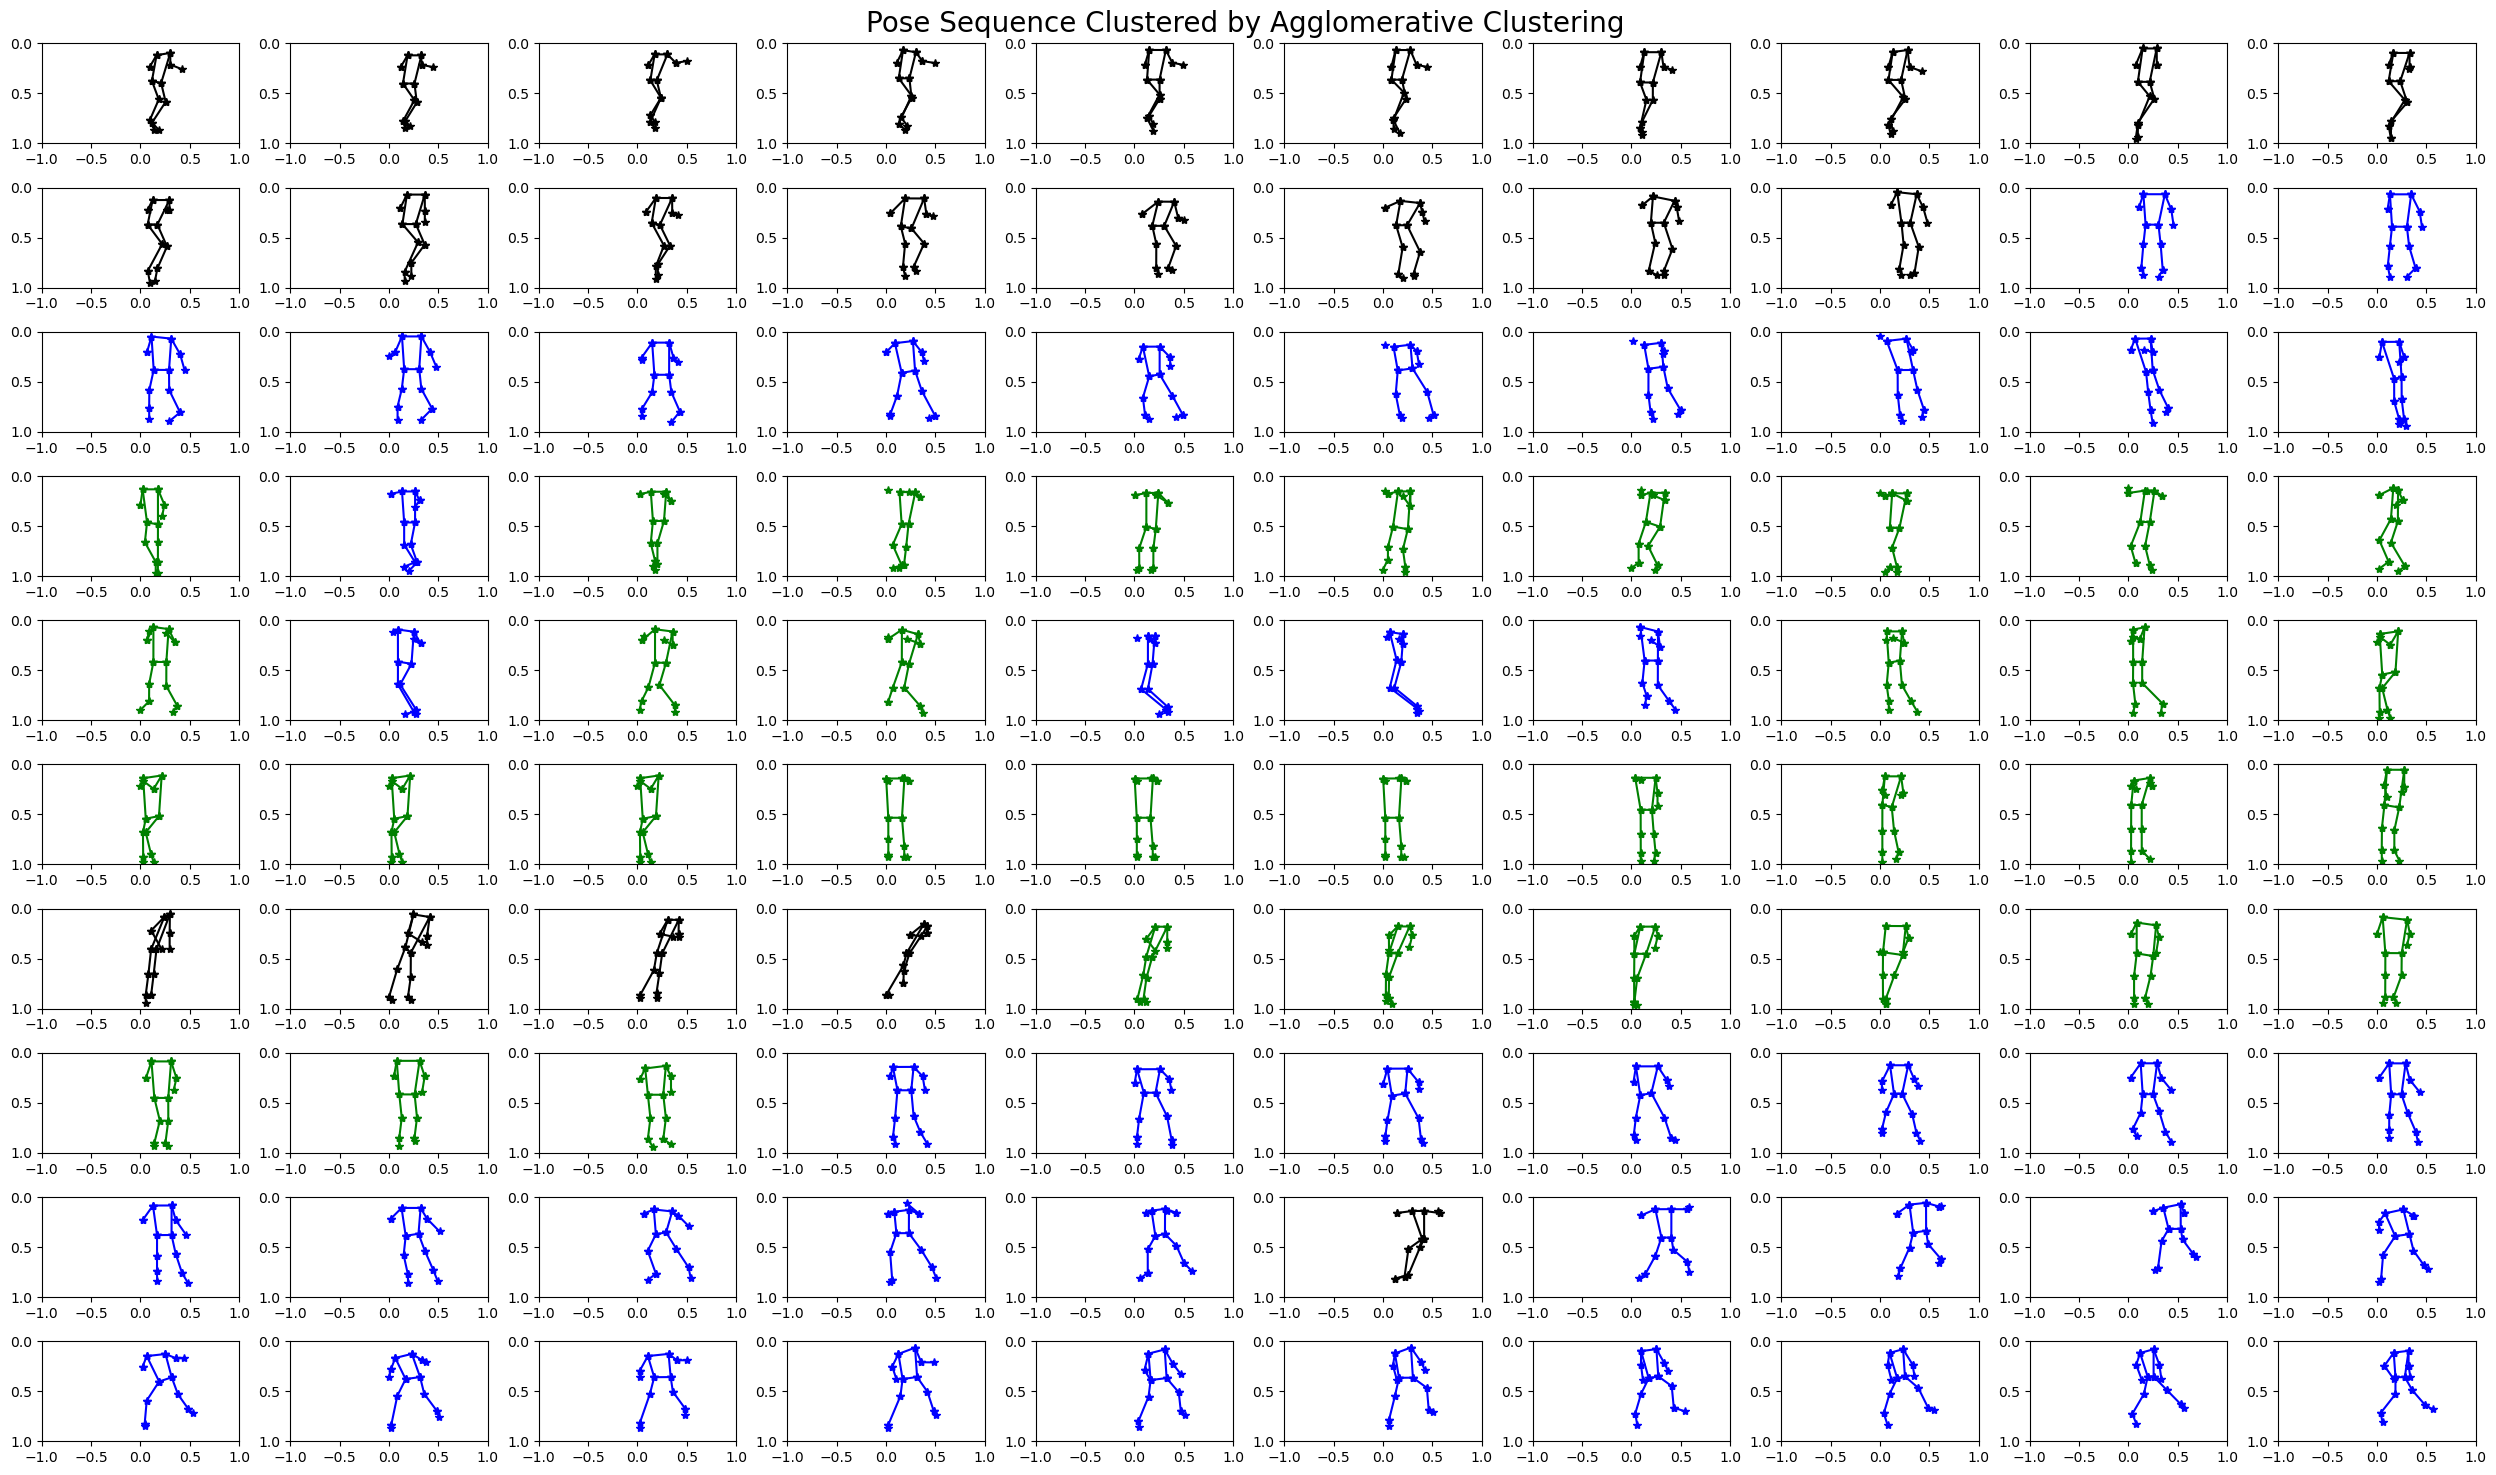

In [36]:
k = 3
agg_clustering = AgglomerativeClustering(n_clusters=k, metric='euclidean', linkage='ward') # change ward to use other distances

# Extract the cluster labels for each pose in the sequence
cluster_labels = agg_clustering.fit_predict(sequence)

# Visualize the pose sequence
plt.figure(figsize=(25,15))
for i in range(len(sequence)):
    plt.subplot(10, 10, i + 1)
    plot_single_pose(sequence[i], c=colors[cluster_labels[i]], head=False)
    plt.ylim(1, 0)
    plt.xlim(-1, 1)
plt.suptitle('Pose Sequence Clustered by Agglomerative Clustering', fontsize=20)
plt.tight_layout()
plt.show()



---
**Task 12 (easy): Agglomerative clustreing algorithm mean pose👩‍💻**
1. The `AgglomerativeClustering()`
 class does not have an attribute or a method for directly extracting cluster centers. Calculate the mean pose within each cluster for $k = 3$  and plot it.
2. Change the distance metric (try `l1`
 and `cosine`
) and repeat the previous two tasks ([Task 10](#loading10), [Task 11](#loading11) and [Task 12](#loading12).1). 
3. What differences do you observe, and can you explain why these differences occur? Does a different distance metric result in more meaningful clusters?


---

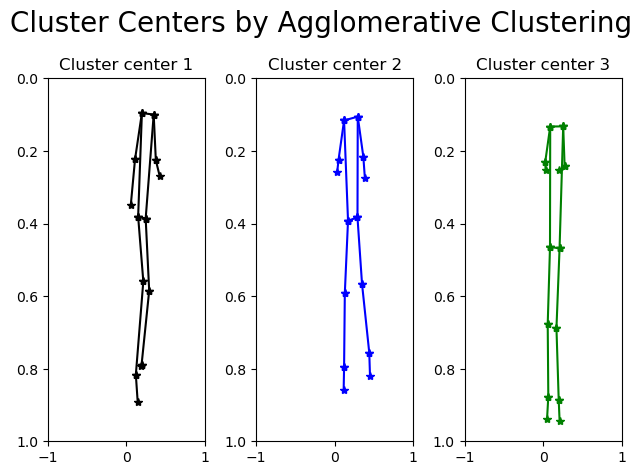

In [37]:
# Calculate the mean pose for each cluster for k=3
cluster_means = np.zeros((k, D*C))
for i in range(k):
    cluster_means[i] = np.mean(sequence[cluster_labels == i], axis=0)

# Visualize the cluster centers
for i in range(k):
    plt.subplot(1, k, i+1)
    plt.title(f'Cluster center {i+1}')
    plot_single_pose(cluster_means[i], c=colors[i], head=False)
    plt.ylim(1, 0)
    plt.xlim(-1, 1)
plt.suptitle('Cluster Centers by Agglomerative Clustering', fontsize=20)
plt.tight_layout()
plt.show() 


In [38]:
# Change the distane metric to l1 and cosine 
# What differences do you observe, and can you explain why these differences occur? Does a different distance metric result in more meaningful clusters?
# Cosine: Measures the cosine of the angle between two vectors
# l1: Absolute positional differences
# Sensitive to small changes

# Euclidean: Distance between two points
# Captures overall variance in the data
# Balanced clusters

# Cosine: Angular similarity
# Good at capturing the direction of the poses
# Clusters based on the direction of the poses

## Comparison

---
**Task 13 (medium): Compare and reflect on the methods👩‍💻💡**
1. Compare the clustered poses obtained with the different clustering methods (K-means, Mean-shift and Agglomerative clustering). What are the similarities and differences between the pose clusters across methods?
2. Why can clusters look similar across methods? 
3. What are the main reasons behind differences in the clusters?
4. The algorithms use different methods for determining the number of clusters. How do these differences impact the results for the pose data?


---

In [39]:
# Reflection:
# K-means: Fixed number of clusters, assumes spherical shapes, good for balanced data but sensitive to initialization and outliers.
# Mean-Shift: Determines clusters based on density, flexible for non-spherical clusters, can over-segment dense regions.
# Agglomerative: Hierarchical, reveals relationships at different levels, flexible with arbitrary shapes via linkage methods.
# Similarities arise from data's inherent structure and common distance metrics.
# Differences stem from cluster shape assumptions, sensitivity to outliers, and methods for determining the number of clusters.
# Impact: K-means simplifies structure, Mean-Shift captures fine variations, Agglomerative allows multi-scale exploration.
